# 01 — Ham Veri Keşfi

Ham veri (`data/raw/arac_verisi.csv`) üzerinde ilk kalite kontrolleri: mükerrer, km=0, km tavanı, eski araçlar, fiyat, şehir ve renk tutarlılığı.

Bulguların karar karşılıkları: `reports/temizleme_kararlari.md`. Temizleme: `python src/temizle.py`.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Verimizi tekrar yüklüyoruz
df_tez = pd.read_csv("../data/raw/arac_verisi.csv")

In [2]:
print("Tekrar eden satır:", df_tez.duplicated().sum())

Tekrar eden satır: 288


In [3]:
print("km == 0:", (df_tez["km"] == 0).sum())
print("km == 300000:", (df_tez["km"] == 300000).sum())

print("\n--- Sıfır KM Olan Araçların Yılları ---")
print(df_tez[df_tez["km"] == 0]["year"].value_counts().sort_index())

km == 0: 101
km == 300000: 1784

--- Sıfır KM Olan Araçların Yılları ---
year
2022     9
2023    42
2024    14
2025    36
Name: count, dtype: int64


In [4]:
df_tez["year"].value_counts().sort_index().head(15)

year
1972     1
1973     3
1974     7
1975     1
1977     1
1978     2
1980     2
1981     3
1982     3
1983     8
1984    23
1985    27
1986    25
1987    27
1988    24
Name: count, dtype: int64

count    2.533440e+05
mean     1.115800e+06
std      9.744306e+05
min      1.000000e+05
1%       2.100000e+05
5%       3.100000e+05
50%      8.800000e+05
95%      2.725000e+06
99%      5.275000e+06
max      1.000000e+07
Name: price, dtype: float64


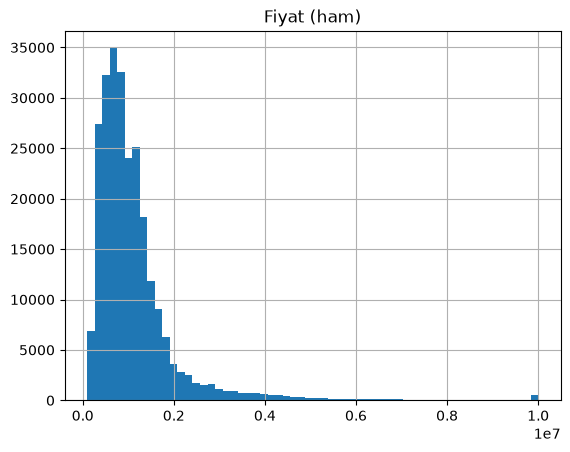

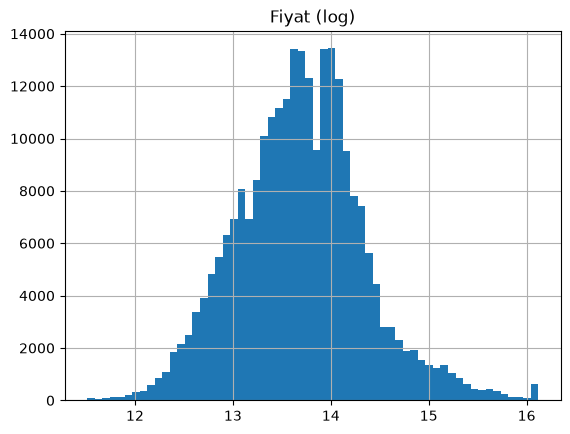

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Fiyatların detaylı yüzdelik dilimleri (Uç değerleri görmek için)
print(df_tez["price"].describe(percentiles=[.01, .05, .5, .95, .99]))

# Ham fiyat grafiği
df_tez["price"].hist(bins=60)
plt.title("Fiyat (ham)")
plt.show()

# Logaritmik fiyat grafiği (Modelin seveceği dönüştürülmüş hali)
np.log(df_tez["price"]).hist(bins=60)
plt.title("Fiyat (log)")
plt.show()

In [7]:
(df_tez.groupby("brand")["price"]
       .agg(adet="count", medyan="median")
       .sort_values("medyan", ascending=False)
       .head(10))

,adet,medyan
brand,,
porsche,783,6790000.0
tesla,788,2575000.0
mercedes,14313,1965000.0
bmw,18365,1669000.0
audi,11212,1630000.0
skoda,9286,1249000.0
honda,9322,1155000.0
volvo,1909,1115000.0
mini,623,1100000.0


In [8]:
print("Şehir sayısı:", df_tez["city"].nunique())
print("\n--- İlk 10 Renk Dağılımı ---")
print(df_tez["color"].value_counts().head(10))
print("\nMarka sayısı:", df_tez["brand"].nunique())

Şehir sayısı: 83

--- İlk 10 Renk Dağılımı ---
color
White          104807
Gray            36014
Black           33281
Silver Gray     20613
Blue            13872
Red             13130
Smoke Gray      13063
Navy             5751
Brown            2784
Burgundy         2533
Name: count, dtype: int64

Marka sayısı: 26


In [9]:
# Tüm şehirleri alfabetik sırayla yazdıralım ki fazlalıklar gözümüze çarpsın
print(sorted(df_tez["city"].unique()))

['Adana', 'Adıyaman', 'Afyonkarahisar', 'Aksaray', 'Amasya', 'Ankara', 'Antalya', 'Ardahan', 'Artvin', 'Aydın', 'Ağrı', 'Balıkesir', 'Bartın', 'Batman', 'Bayburt', 'Bilecik', 'Bingöl', 'Bitlis', 'Bolu', 'Burdur', 'Bursa', 'Denizli', 'Diyarbakır', 'Diğer', 'Düzce', 'Edirne', 'Elazığ', 'Erzincan', 'Erzurum', 'Eskişehir', 'Gaziantep', 'Giresun', 'Gümüşhane', 'Hakkari', 'Hatay', 'Isparta', 'Iğdır', 'Kahramanmaraş', 'Karabük', 'Karaman', 'Kardzhali', 'Kars', 'Kastamonu', 'Kayseri', 'Kilis', 'Kocaeli', 'Konya', 'Kütahya', 'Kırklareli', 'Kırıkkale', 'Kırşehir', 'Malatya', 'Manisa', 'Mardin', 'Mersin', 'Muğla', 'Muş', 'Nevşehir', 'Niğde', 'Ordu', 'Osmaniye', 'Rize', 'Sakarya', 'Samsun', 'Siirt', 'Sinop', 'Sivas', 'Tekirdağ', 'Tokat', 'Trabzon', 'Tunceli', 'Uşak', 'Van', 'Yalova', 'Yozgat', 'Zonguldak', 'Çanakkale', 'Çankırı', 'Çorum', 'İstanbul', 'İzmir', 'Şanlıurfa', 'Şırnak']


In [10]:
# Sadece 2024 model araçları filtreleyelim
df_2024 = df_tez[df_tez["year"] == 2024].copy()

# Araç 0 km ise "Sıfır", değilse "İkinci El" yazan geçici bir sütun oluşturalım
df_2024["durum"] = np.where(df_2024["km"] == 0, "Sıfır KM", "İkinci El")

# Duruma göre gruplayıp ilan sayısını ve medyan fiyatı (ortadaki fiyatı) bulalım
karsilastirma_2024 = df_2024.groupby("durum")["price"].agg(
    ilan_sayisi="count", 
    medyan_fiyat="median"
)

print("--- 2024 Model Araçlarda Fiyat Karşılaştırması ---")
print(karsilastirma_2024)

--- 2024 Model Araçlarda Fiyat Karşılaştırması ---
           ilan_sayisi  medyan_fiyat
durum                               
Sıfır KM            14    10000000.0
İkinci El         7311     1510000.0
